# 02 - Modeling: Do serum ncRNAs (miRNAs) predict AD beyond clinical factors?

**Objective 2** (Specific Aims 2.1-2.3). Data: GSE120584 serum miRNA, **training split only**, AD vs NC.

| Feature set | Features |
|---|---|
| **A_clinical** | age, sex, APOE4 (baseline; same as the benchmark paper's clinical model) |
| **A2_clinical+quality** | A + sample detection rate (technical quality) |
| **B_ncrna** | miRNAs only |
| **C_ncrna+clinical** | miRNAs + age, sex, APOE4, detection rate |

**Key question:** AUC(C) - AUC(A2) = what the ncRNAs add on top of everything else.

**Method:** nested cross-validation. Outer 5-fold gives the performance estimate; inner 3-fold tunes
hyperparameters and the number of miRNAs kept (k = 50 / 200 / all 817). Scaling and feature selection
are re-fit inside every fold (no leakage). Class imbalance (816 AD vs 230 NC) handled with class weights.
The held-out test set is **not** used here.

In [1]:
import sys, json, warnings
sys.path.append("../src")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score

from utils import load_dataset, ROOT, FIGURES, SEED
from modeling import (FEATURE_SETS, classifiers, nested_cv, make_features, detection_rate,
                      bootstrap_auc_ci, bootstrap_auc_diff, metrics)

FIG = FIGURES / "02_modeling"; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / "results" / "tables"
MOD = ROOT / "results" / "models"; MOD.mkdir(parents=True, exist_ok=True)
CACHE = MOD / "02_nested_cv_results.joblib"
RERUN = False   # set True to recompute (about 10 minutes)

sns.set_theme(style="whitegrid")
def savefig(name): plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data

In [2]:
X, clin = load_dataset("GSE120584_serum", split="train", diagnoses=["AD", "NC"])
clin["detect_rate"] = detection_rate(X)          # per-sample, computed on all miRNAs

ncrna = pd.read_csv(TAB / "01_eda_filtered_mirnas.csv")["miRNA"].tolist()   # 817 miRNAs (>=80% detected)
F = make_features(X[ncrna], clin)
y = (clin["diagnosis"] == "AD").astype(int)

print(f"Samples: {len(y)} (AD {y.sum()}, NC {(1 - y).sum()}),  miRNA features: {len(ncrna)}")

Samples: 1046 (AD 816, NC 230),  miRNA features: 817


## 2. Nested cross-validation (all feature sets x all algorithms)

In [3]:
algos = list(classifiers().keys())

if CACHE.exists() and not RERUN:
    res = joblib.load(CACHE)
    print("Loaded cached results:", CACHE.relative_to(ROOT))
else:
    res = {}
    for fs in FEATURE_SETS:
        for algo in algos:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                folds, oof, _ = nested_cv(F, y, ncrna, fs, algo)
            res[(fs, algo)] = {"folds": folds, "oof": oof}
            print(f"{fs:22s} {algo:13s} AUC {folds.AUC.mean():.3f} +/- {folds.AUC.std():.3f}")
    joblib.dump(res, CACHE)

A_clinical             LogReg        AUC 0.837 +/- 0.030


A_clinical             RandomForest  AUC 0.828 +/- 0.017


A_clinical             SVM           AUC 0.839 +/- 0.025


A_clinical             KNN           AUC 0.796 +/- 0.035


A_clinical             GradBoost     AUC 0.834 +/- 0.023


A_clinical             XGBoost       AUC 0.835 +/- 0.023


... (14 outputs left out)

C_ncrna+clinical       SVM           AUC 0.870 +/- 0.021


C_ncrna+clinical       KNN           AUC 0.830 +/- 0.033


C_ncrna+clinical       GradBoost     AUC 0.899 +/- 0.027


C_ncrna+clinical       XGBoost       AUC 0.907 +/- 0.021


## 3. Results

In [4]:
rows = []
for (fs, algo), r in res.items():
    f, oof = r["folds"], r["oof"]
    lo, hi = bootstrap_auc_ci(y, oof["score"])
    rows.append({"feature_set": fs, "algorithm": algo,
                 "AUC_mean": f.AUC.mean(), "AUC_sd": f.AUC.std(),
                 "AUC_pooled": roc_auc_score(y, oof["score"]), "AUC_95CI": f"{lo:.3f}-{hi:.3f}",
                 "sensitivity": f.sensitivity.mean(), "specificity": f.specificity.mean(),
                 "balanced_acc": f.balanced_acc.mean(), "F1": f.F1.mean()})
summary = pd.DataFrame(rows)
summary.to_csv(TAB / "02_model_comparison.csv", index=False)
summary.sort_values("AUC_mean", ascending=False).round(3)

,feature_set,algorithm,AUC_mean,AUC_sd,AUC_pooled,AUC_95CI,sensitivity,specificity,balanced_acc,F1
23,C_ncrna+clinical,XGBoost,0.907,0.021,0.910,0.886-0.932,0.955,0.661,0.808,0.931
18,C_ncrna+clinical,LogReg,0.900,0.025,0.900,0.875-0.922,0.853,0.813,0.833,0.895
22,C_ncrna+clinical,GradBoost,0.899,0.027,0.887,0.861-0.912,0.947,0.604,0.776,0.920
20,C_ncrna+clinical,SVM,0.870,0.021,0.867,0.835-0.896,0.946,0.643,0.795,0.924
19,C_ncrna+clinical,RandomForest,0.858,0.041,0.859,0.830-0.888,0.967,0.422,0.694,0.908
17,B_ncrna,XGBoost,0.850,0.032,0.845,0.812-0.878,0.958,0.548,0.753,0.919
14,B_ncrna,SVM,0.845,0.027,0.848,0.811-0.881,0.961,0.604,0.783,0.927
8,A2_clinical+quality,SVM,0.844,0.030,0.842,0.814-0.871,0.830,0.696,0.763,0.866
6,A2_clinical+quality,LogReg,0.842,0.027,0.834,0.803-0.864,0.765,0.752,0.758,0.832
9,A2_clinical+quality,KNN,0.841,0.044,0.838,0.808-0.866,0.951,0.465,0.708,0.905


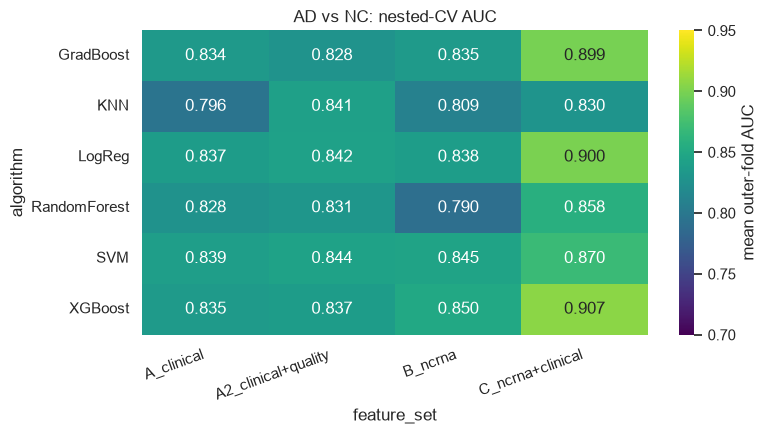

In [5]:
pivot = summary.pivot(index="algorithm", columns="feature_set", values="AUC_mean")[list(FEATURE_SETS)]
plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", vmin=0.7, vmax=0.95, cbar_kws={"label": "mean outer-fold AUC"})
plt.title("AD vs NC: nested-CV AUC"); plt.xticks(rotation=20, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); savefig("auc_heatmap"); plt.show()

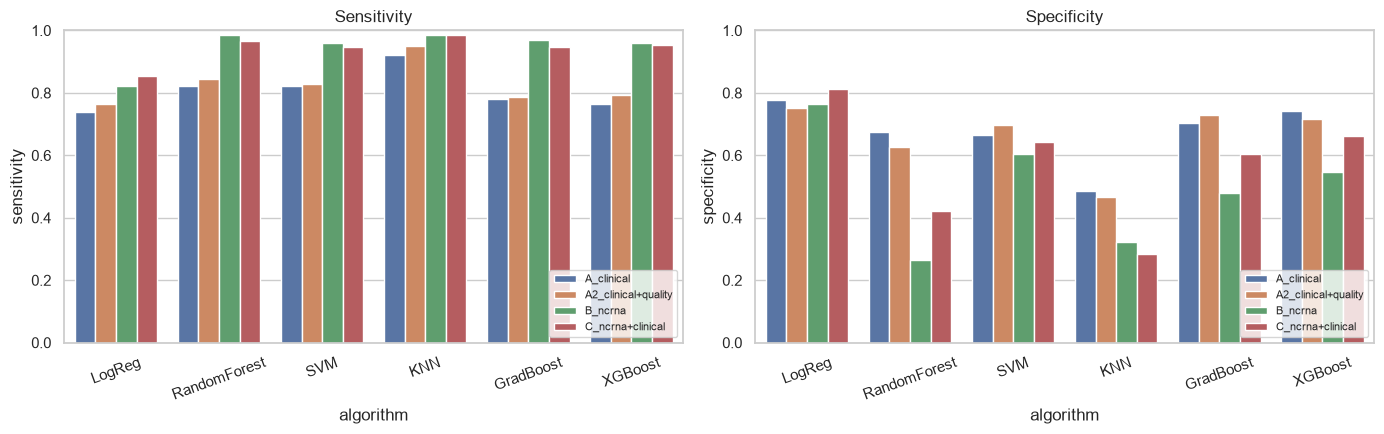

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["sensitivity", "specificity"]):
    sns.barplot(data=summary, x="algorithm", y=metric, hue="feature_set", hue_order=list(FEATURE_SETS), ax=ax)
    ax.set_ylim(0, 1); ax.set_title(metric.capitalize()); ax.legend(fontsize=8, loc="lower right")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); savefig("sens_spec"); plt.show()

## 4. Added value of ncRNAs (the key result)

Paired bootstrap on the pooled out-of-fold predictions (same samples, 2000 resamples).
`p` = fraction of bootstrap samples where the ncRNA model is **not** better (one-sided).

In [7]:
gain_rows = []
for algo in algos:
    for base in ["A_clinical", "A2_clinical+quality"]:
        d, lo, hi, p = bootstrap_auc_diff(y, res[(base, algo)]["oof"]["score"],
                                          res[("C_ncrna+clinical", algo)]["oof"]["score"])
        gain_rows.append({"algorithm": algo, "baseline": base, "AUC_gain": d,
                          "CI_low": lo, "CI_high": hi, "p_one_sided": p})
gain = pd.DataFrame(gain_rows)
gain.to_csv(TAB / "02_ncrna_added_value.csv", index=False)
gain.round(3)

,algorithm,baseline,AUC_gain,CI_low,CI_high,p_one_sided
0,LogReg,A_clinical,0.071,0.046,0.098,0.000
1,LogReg,A2_clinical+quality,0.066,0.041,0.092,0.000
2,RandomForest,A_clinical,0.035,-0.002,0.072,0.036
3,RandomForest,A2_clinical+quality,0.029,-0.006,0.063,0.055
4,SVM,A_clinical,0.030,-0.007,0.067,0.059
5,SVM,A2_clinical+quality,0.024,-0.014,0.061,0.098
6,KNN,A_clinical,0.027,-0.017,0.069,0.116
7,KNN,A2_clinical+quality,-0.016,-0.054,0.020,0.817
8,GradBoost,A_clinical,0.060,0.032,0.091,0.000
9,GradBoost,A2_clinical+quality,0.063,0.036,0.092,0.000


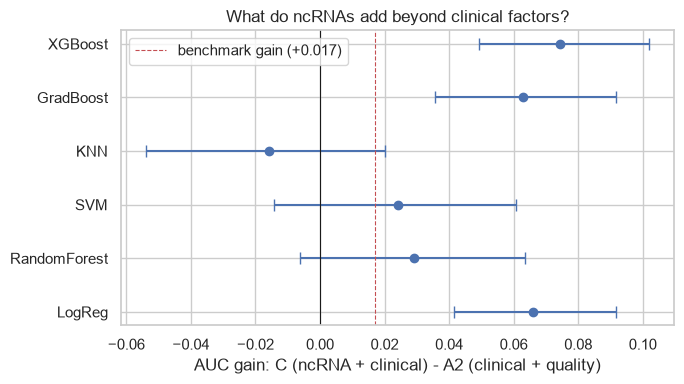

In [8]:
g = gain[gain.baseline == "A2_clinical+quality"].set_index("algorithm")
plt.figure(figsize=(7, 4))
plt.errorbar(g.AUC_gain, g.index, xerr=[g.AUC_gain - g.CI_low, g.CI_high - g.AUC_gain], fmt="o", capsize=4)
plt.axvline(0, c="k", lw=.8); plt.axvline(0.017, c="r", ls="--", lw=.8, label="benchmark gain (+0.017)")
plt.xlabel("AUC gain: C (ncRNA + clinical) - A2 (clinical + quality)"); plt.legend()
plt.title("What do ncRNAs add beyond clinical factors?"); plt.tight_layout(); savefig("added_value"); plt.show()

## 5. ROC curves (best algorithm per feature set)

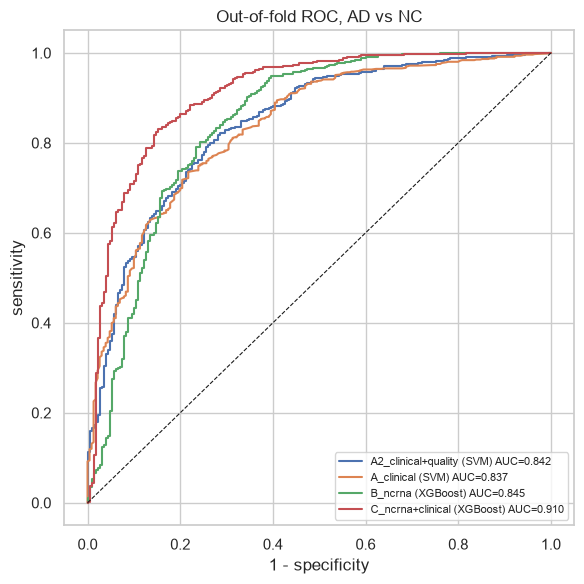

In [9]:
best_per_fs = summary.loc[summary.groupby("feature_set").AUC_mean.idxmax()]
plt.figure(figsize=(6, 6))
for _, r in best_per_fs.iterrows():
    oof = res[(r.feature_set, r.algorithm)]["oof"]
    fpr, tpr, _ = roc_curve(y, oof["score"])
    plt.plot(fpr, tpr, label=f"{r.feature_set} ({r.algorithm}) AUC={r.AUC_pooled:.3f}")
plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("1 - specificity"); plt.ylabel("sensitivity"); plt.legend(fontsize=8, loc="lower right")
plt.title("Out-of-fold ROC, AD vs NC"); plt.tight_layout(); savefig("roc_best"); plt.show()

## 6. Comparison with the benchmark (Shigemizu et al., 2019)

Not identical setups: they used a 50/50 split and supervised PCA; we use nested CV on 80% of the data.
Treat as a rough reference, not a head-to-head test.

In [10]:
bestC = summary[summary.feature_set == "C_ncrna+clinical"].sort_values("AUC_mean", ascending=False).iloc[0]
bestA = summary[summary.feature_set == "A_clinical"].sort_values("AUC_mean", ascending=False).iloc[0]
bench = pd.DataFrame([
    {"study": "Shigemizu 2019", "model": "clinical only (age, sex, APOE)", "AUC": 0.857, "specificity": None},
    {"study": "Shigemizu 2019", "model": "78 miRNAs", "AUC": 0.874, "specificity": 0.660},
    {"study": "This project", "model": f"clinical only ({bestA.algorithm})", "AUC": round(bestA.AUC_mean, 3),
     "specificity": round(bestA.specificity, 3)},
    {"study": "This project", "model": f"ncRNA + clinical ({bestC.algorithm})", "AUC": round(bestC.AUC_mean, 3),
     "specificity": round(bestC.specificity, 3)},
])
bench

,study,model,AUC,specificity
0,Shigemizu 2019,"clinical only (age, sex, APOE)",0.857,NaN
1,Shigemizu 2019,78 miRNAs,0.874,0.660
2,This project,clinical only (SVM),0.839,0.665
3,This project,ncRNA + clinical (XGBoost),0.907,0.661


## 7. Select the final model

Rule (from the analysis plan): highest mean outer-fold AUC for feature set C; if two models are within
0.005 AUC, prefer the simpler one (LogReg < SVM < KNN < RandomForest < GradBoost < XGBoost).
Hyperparameters for the final fit = most frequently chosen across the 5 outer folds.

In [11]:
SIMPLICITY = ["LogReg", "SVM", "KNN", "RandomForest", "GradBoost", "XGBoost"]
c = summary[summary.feature_set == "C_ncrna+clinical"].copy()
top = c.AUC_mean.max()
c = c[c.AUC_mean >= top - 0.005]
c["rank"] = c.algorithm.map(SIMPLICITY.index)
chosen = c.sort_values("rank").iloc[0]

params = res[("C_ncrna+clinical", chosen.algorithm)]["folds"]["best_params"].map(lambda d: json.dumps(d, sort_keys=True))
final_params = json.loads(params.value_counts().index[0])

choice = {"feature_set": "C_ncrna+clinical", "algorithm": chosen.algorithm,
          "cv_AUC_mean": round(chosen.AUC_mean, 4), "cv_AUC_sd": round(chosen.AUC_sd, 4),
          "params": final_params, "ncrna_features": "results/tables/01_eda_filtered_mirnas.csv"}
json.dump(choice, open(MOD / "02_final_model_choice.json", "w"), indent=2)
print(json.dumps(choice, indent=2))
print("\nAll models within 0.005 of the best:", ", ".join(c.algorithm))

{
  "feature_set": "C_ncrna+clinical",
  "algorithm": "XGBoost",
  "cv_AUC_mean": 0.9069,
  "cv_AUC_sd": 0.0206,
  "params": {
    "clf__learning_rate": 0.05,
    "clf__max_depth": 4,
    "features__ncrna__select__k": "all"
  },
  "ncrna_features": "results/tables/01_eda_filtered_mirnas.csv"
}

All models within 0.005 of the best: XGBoost


## 8. Findings to record (fill in)

- Clinical-only baseline AUC:
- Best ncRNA + clinical AUC (algorithm):
- AUC gain from ncRNAs over clinical + quality (CI):
- ncRNA-only AUC (how strong are miRNAs on their own?):
- Specificity of the chosen model vs benchmark (0.66):
- Chosen final model:

### Next
1. **03 - Biomarker identification:** LASSO / RFE / RF importance + SHAP on the chosen model, inside CV, to get the top 10 ncRNAs (Objective 3).
2. **04 - Final evaluation:** fit the chosen model on the full training split, evaluate **once** on the held-out test set.
3. **05 - External validation:** GSE215789 (MCI), GSE305625, GSE46579.
4. **06 - lncRNA / circRNA:** GSE248417.